# Classes 5+6: Potential outcomes, the Neyman–Rubin model and selection bias

*Econometria Avançada, MPE Insper.* Written from the draft class plan before the lecturer's site was loaded; on the official schedule (`Map/class-plan.md`) this material belongs to Classes 5+6. The lecturer's notes for the block: `Aula/class-05-06/materials/notes-on-causal-inference.pdf`.

| | |
|---|---|
| **Read** | Angrist & Pischke, *Mostly Harmless Econometrics* (MHE), Ch. 1 "Questions about Questions" and Ch. 2 "The Experimental Ideal", printed pp. 3–18 |
| **Goals** | define potential outcomes and the ATE/ATT/ATU; split an observed difference into ATT + selection bias; show why random assignment removes the selection term; read an experiment as a regression |
| **Topic rules** | `rules/02_causalidade_potential_outcomes.md` |
| **Video** | `Videos/class-01-potential-outcomes/` (same 8-person table as below) |

**Interactive companions** (private links; HTML sources sit next to this notebook):

| Companion | Question it answers | Local file |
|---|---|---|
| [Selection Bias Decomposer](https://claude.ai/artifact/NQH4xcffymY5roEKXjkpWv) | What is the naive gap made of? | `companion-selection-bias.html` |
| [Bigger Sample, Same Bias](https://claude.ai/artifact/9wN4ftRgB32YbgFeYa1jG9) | Does more data fix selection bias? | `companion-sample-size.html` |
| [The Eight-Person Table](https://claude.ai/artifact/KTnW6qcwYkexQ1sz9PYzzo) | What does random assignment buy on a table I can see completely? | `companion-eight-person-table.html` |

**Running this notebook.** Python kernel (numpy, scipy, matplotlib). The course language is R, but R is not installed on this machine, so the R version of the core simulation is in §11 as a reference cell that has not been run.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(20261009)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
# Colour roles shared with the video and the companions
ORANGE, BLUE, GREEN, RED, GREY = "#c76f1c", "#2b63c4", "#23864d", "#c63a30", "#98a2b3"

## 1. Four questions before any regression (MHE Ch. 1, pp. 3–7)

MHE organises a research project around four *Frequently Asked Questions*:

1. **What is the causal relationship of interest?** A causal effect tells you what would happen in a counterfactual world, e.g. the wage increment a person would get from more schooling (≈ 40% for a college degree, p. 3).
2. **What experiment would ideally capture it?** Imagine no budget and no ethics committee. If no experiment can answer the question, even in principle, it is *FUQ'd*, a "fundamentally unidentified question". Example (p. 5): the effect of school start age on first-grade test scores, because start age = current age − time in school, so the three cannot be separated while children are in school.
3. **What is your identification strategy?** How observational data approximate the ideal experiment (Angrist & Krueger's quarter-of-birth design, p. 6).
4. **What is your mode of statistical inference?** Population, sample, and the assumptions behind the standard errors (p. 6).

The rest of the class is about why question 2 is the benchmark: a randomised trial.

## 2. The puzzle: do hospitals make people sick? (MHE §2.1, p. 10)

The 2005 NHIS asks whether the respondent spent a night in hospital in the past 12 months, and self-rated health on a 1 (excellent) to 5 (poor) scale:

| Group | Sample size | Mean health status | Std. error |
|---|---|---|---|
| Hospital | 7,774 | 2.79 | 0.014 |
| No hospital | 90,049 | 2.07 | 0.003 |

The difference is 0.71 with $t = 58.9$ (MHE p. 10). Taken at face value, hospitals make people sicker. The obvious objection: **people who go to hospital were less healthy to begin with.**

Brazil shows the same pattern (IBGE SIDRA table 5082, PNS 2013; share hospitalised ≥ 24 h in the past 12 months): very good/good health 4.5%, regular 8.8%, bad/very bad 18.8%. The arrow plausibly runs from health to hospital, the reverse of the causal question.

A large $t$ says the gap is *precisely* estimated. It says nothing about whether the gap is the causal effect. §8 makes that distinction concrete.

## 3. Potential outcomes (MHE §2.1, p. 11)

Treatment is binary, $d_i \in \{0, 1\}$. Each individual has **two potential outcomes**:

$$
\text{potential outcome} = \begin{cases} y_{1i} & \text{if } d_i = 1 \\ y_{0i} & \text{if } d_i = 0 \end{cases}
$$

$y_{0i}$ is $i$'s health had they not gone to hospital, *whether or not they actually went*; $y_{1i}$ is their health if they go. The individual causal effect is $y_{1i} - y_{0i}$.

**Switching equation (MHE eq. 2.1.1).** The observed outcome is

$$
y_i = \begin{cases} y_{1i} & \text{if } d_i = 1 \\ y_{0i} & \text{if } d_i = 0 \end{cases}
\;=\; y_{0i} + (y_{1i} - y_{0i})\, d_i .
$$

Check: $d_i = 0$ gives $y_{0i}$; $d_i = 1$ gives $y_{0i} + y_{1i} - y_{0i} = y_{1i}$.

**The fundamental problem of causal inference** (Holland 1986, cited in MHE p. 11 fn. 2): for each person we observe only one of the two potential outcomes, so individual effects are never seen. We must learn about *averages* by comparing people.

**What the notation assumes.** Writing $y_{1i}, y_{0i}$ as functions of $i$'s own $d_i$ only builds in two assumptions, usually called SUTVA (Rubin 1974, 1977, the references in MHE fn. 2; MHE Ch. 2 does not name it):
- *no interference*: my outcome does not depend on whether *you* are treated (fails with contagion in a hospital ward, or with general-equilibrium effects of a large training programme);
- *one version of treatment*: "hospitalised" means the same thing for everyone.

## 4. Estimands: ATE, ATT, ATU

| Estimand | Definition | Question it answers |
|---|---|---|
| ATE | $E[y_{1i} - y_{0i}]$ | Effect for a randomly chosen person |
| ATT | $E[y_{1i} - y_{0i} \mid d_i = 1]$ | Effect for those who were treated (MHE's "average treatment effect on the treated", p. 11) |
| ATU | $E[y_{1i} - y_{0i} \mid d_i = 0]$ | Effect for those who were not |

With $\pi = P(d_i = 1)$, the law of iterated expectations gives

$$
\text{ATE} = \pi \cdot \text{ATT} + (1-\pi)\cdot \text{ATU}.
$$

The three coincide when the effect is the same for everyone, or when treatment is unrelated to the effect.

### A table where both worlds are visible

The table below is invented for teaching, with a health index from 0 to 10 where **higher is healthier** (the reverse of the NHIS scale). The sick (Ana to Davi) go to hospital.

In [2]:
names = ["Ana", "Bruno", "Carla", "Davi", "Elisa", "Fábio", "Gabi", "Hugo"]
y0 = np.array([3, 2, 4, 3, 8, 9, 7, 8], dtype=float)   # health without hospital
y1 = np.array([5, 5, 6, 4, 8, 8, 8, 9], dtype=float)   # health with hospital
d  = np.array([1, 1, 1, 1, 0, 0, 0, 0])                # the sick self-select
y  = y0 + (y1 - y0) * d                                # switching equation, MHE 2.1.1

print(f"{'person':<7}{'Y0':>5}{'Y1':>5}{'Y1-Y0':>7}{'D':>4}{'Y obs':>7}")
for row in zip(names, y0, y1, y1 - y0, d, y):
    print(f"{row[0]:<7}{row[1]:>5.0f}{row[2]:>5.0f}{row[3]:>7.0f}{row[4]:>4d}{row[5]:>7.0f}")

effect = y1 - y0
ATE, ATT, ATU = effect.mean(), effect[d == 1].mean(), effect[d == 0].mean()
pi = d.mean()
print(f"\nATE = {ATE:.3f}   ATT = {ATT:.3f}   ATU = {ATU:.3f}   pi = {pi:.2f}")
assert np.isclose(ATE, pi * ATT + (1 - pi) * ATU)

person    Y0   Y1  Y1-Y0   D  Y obs
Ana        3    5      2   1      5
Bruno      2    5      3   1      5
Carla      4    6      2   1      6
Davi       3    4      1   1      4
Elisa      8    8      0   0      8
Fábio      9    8     -1   0      9
Gabi       7    8      1   0      7
Hugo       8    9      1   0      8

ATE = 1.125   ATT = 2.000   ATU = 0.250   pi = 0.50


Hospital helps every treated person (effects 2, 3, 2, 1), and the average effect is positive. A researcher sees only the `Y obs` column.

## 5. The selection-bias decomposition (MHE §2.1, p. 11)

The naive comparison of averages by treatment status is $E[y_i \mid d_i = 1] - E[y_i \mid d_i = 0]$. By the switching equation, $E[y_i \mid d_i = 1] = E[y_{1i} \mid d_i = 1]$ and $E[y_i \mid d_i = 0] = E[y_{0i} \mid d_i = 0]$. Add and subtract the counterfactual $E[y_{0i} \mid d_i = 1]$, the untreated health of the treated:

$$
\begin{aligned}
\underbrace{E[y_i \mid d_i=1] - E[y_i \mid d_i=0]}_{\text{observed difference}}
&= E[y_{1i} \mid d_i=1] - E[y_{0i} \mid d_i=1] + E[y_{0i} \mid d_i=1] - E[y_{0i} \mid d_i=0] \\
&= \underbrace{E[y_{1i} - y_{0i} \mid d_i=1]}_{\text{ATT}} \;+\; \underbrace{E[y_{0i} \mid d_i=1] - E[y_{0i} \mid d_i=0]}_{\text{selection bias}} .
\end{aligned}
$$

**Selection bias** is the difference in *untreated* outcomes between those who were and were not treated. In the hospital case the sick select in, so $E[y_{0i} \mid d_i=1] < E[y_{0i} \mid d_i=0]$: the bias is negative and "may be so large … that it completely masks a positive treatment effect" (MHE p. 12).

### The ATE version

Use $\text{ATT} = \text{ATE} + (1-\pi)(\text{ATT} - \text{ATU})$, which is the identity from §4 rearranged:

$$
\text{observed difference} = \text{ATE} + \underbrace{E[y_{0i} \mid d_i=1] - E[y_{0i} \mid d_i=0]}_{\text{selection bias}} + \underbrace{(1-\pi)(\text{ATT} - \text{ATU})}_{\text{heterogeneity bias}} .
$$

The second bias appears when the people who choose treatment are those who gain most (or least) from it. This extension is standard but is not written out in MHE Ch. 2.

In [3]:
naive = y[d == 1].mean() - y[d == 0].mean()
SB    = y0[d == 1].mean() - y0[d == 0].mean()
het   = (1 - pi) * (ATT - ATU)

print(f"naive gap                 = {naive:.3f}")
print(f"ATT + SB                  = {ATT:.3f} + ({SB:.3f}) = {ATT + SB:.3f}")
print(f"ATE + SB + (1-pi)(ATT-ATU) = {ATE:.3f} + ({SB:.3f}) + {het:.3f} = {ATE + SB + het:.3f}")
assert np.isclose(naive, ATT + SB) and np.isclose(naive, ATE + SB + het)

naive gap                 = -3.000
ATT + SB                  = 2.000 + (-5.000) = -3.000
ATE + SB + (1-pi)(ATT-ATU) = 1.125 + (-5.000) + 0.875 = -3.000


The data "say" hospital costs 3 health points. In fact it adds 2 points for the treated; a selection bias of −5 swallows the effect and flips its sign. Try it yourself in [The Eight-Person Table](https://claude.ai/artifact/KTnW6qcwYkexQ1sz9PYzzo) (choose who is treated, toggle the god's view).

### Which way does the bias go? Examples from MHE (pp. 12–16)

| Setting | Who selects in | Sign of selection bias | Naive comparison |
|---|---|---|---|
| Hospitals (NHIS) | the sick | negative | hospitals look harmful |
| Subsidised training programmes | workers with low earnings potential | negative | trainees earn *less* than comparison groups; randomised evaluations mostly find positive effects (p. 13) |
| Hormone replacement therapy | (implied) healthier women | positive | Nurses Health Study shows better health among users; the randomised trial shows few benefits and serious side effects (p. 12) |
| Class size | weaker students are grouped into smaller classes | negative | small classes look worse; STAR and Angrist–Lavy find a strong positive effect of smaller classes (pp. 13, 16) |

The sign is an economic argument about *who chooses treatment*, not a statistical property.

## 6. Random assignment solves the selection problem (MHE §2.2, p. 12)

Random assignment makes $d_i$ **independent of potential outcomes**: $\{y_{0i}, y_{1i}\} \perp d_i$. Then

$$
\begin{aligned}
E[y_i \mid d_i=1] - E[y_i \mid d_i=0] &= E[y_{1i} \mid d_i=1] - E[y_{0i} \mid d_i=0] \\
&= E[y_{1i} \mid d_i=1] - E[y_{0i} \mid d_i=1] \qquad (\text{independence: swap } d_i=0 \text{ for } d_i=1) \\
&= E[y_{1i} - y_{0i} \mid d_i=1] = E[y_{1i} - y_{0i}] .
\end{aligned}
$$

Selection bias is zero **and** ATT = ATE: "the effect of randomly-assigned hospitalization on the hospitalized is the same as the effect of hospitalization on a randomly chosen patient" (MHE p. 12). The heterogeneity term vanishes too, because independence makes ATT = ATU.

**Unbiased does not mean right every time.** Independence holds *on average over assignments*. On our 8-person table we can enumerate every one of the $\binom{8}{4} = 70$ ways to treat four people:

assignments: 70   mean gap = 1.1250   (ATE = 1.1250)
range -3.00 to 5.25;   wrong sign (<= 0): 17 of 70


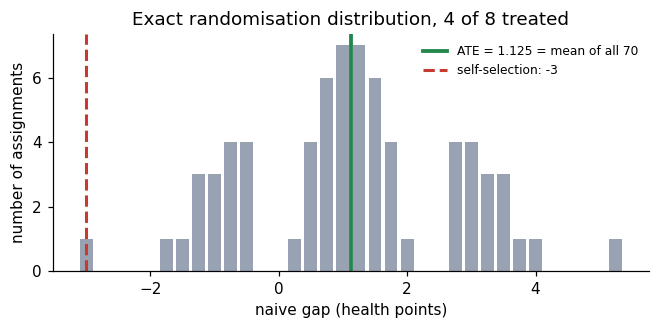

In [4]:
def naive_gap(assign):
    return y1[assign == 1].mean() - y0[assign == 0].mean()

gaps = np.array([naive_gap(np.isin(np.arange(8), c).astype(int))
                 for c in itertools.combinations(range(8), 4)])
print(f"assignments: {gaps.size}   mean gap = {gaps.mean():.4f}   (ATE = {ATE:.4f})")
print(f"range {gaps.min():.2f} to {gaps.max():.2f};   wrong sign (<= 0): {(gaps <= 0).sum()} of {gaps.size}")
assert np.isclose(gaps.mean(), ATE)

vals, counts = np.unique(gaps, return_counts=True)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(vals, counts, width=0.2, color=GREY)
ax.axvline(ATE, color=GREEN, lw=2.5, label=f"ATE = {ATE:.3f} = mean of all 70")
ax.axvline(naive, color=RED, lw=2, ls="--", label=f"self-selection: {naive:.0f}")
ax.set(xlabel="naive gap (health points)", ylabel="number of assignments",
       title="Exact randomisation distribution, 4 of 8 treated")
ax.legend(frameon=False, fontsize=8); plt.show()

The average over all 70 random assignments equals the ATE exactly, yet a single small experiment can land anywhere from −3 to 5.25. That spread is what standard errors measure, and it shrinks with sample size. Selection bias does not shrink, as §8 shows.

## 7. A continuous version (the model behind the companions)

To move parameters continuously, the companions use an **illustrative** data-generating process. It is declared here and is not from MHE:

$$
y_{0i} \sim N(\mu_0, \sigma^2),\quad z_i = \tfrac{y_{0i}-\mu_0}{\sigma},\qquad
y_{1i} = y_{0i} + \tau + \gamma\,(y_{0i} - \mu_0),\qquad
d_i = \mathbf 1\{\lambda z_i + \sqrt{1-\lambda^2}\,\nu_i > c\},\; c = \Phi^{-1}(1-\pi).
$$

- $\tau$ = ATE; $\gamma$ = how the effect varies with untreated health ($\gamma<0$: the sick gain more);
- $\lambda$ = correlation between $z_i$ and the latent index ($\lambda<0$: the sick select in; $\lambda=0$: a coin flip); $\pi$ = share treated.

The latent index $s_i = \lambda z_i + \sqrt{1-\lambda^2}\nu_i$ is standard normal with $\text{corr}(z_i, s_i) = \lambda$, so $E[z_i \mid s_i] = \lambda s_i$ and the truncated-normal means give

$$
E[z \mid d=1] = \lambda\frac{\phi(c)}{\pi},\qquad E[z \mid d=0] = -\lambda\frac{\phi(c)}{1-\pi},
$$
$$
\text{SB} = \sigma\lambda\frac{\phi(c)}{\pi(1-\pi)},\qquad \text{ATT} = \tau + \gamma\sigma E[z\mid d=1],\qquad \text{ATU} = \tau + \gamma\sigma E[z\mid d=0].
$$

Below, the closed forms are checked against a simulated population of one million people. Explore it in the [Selection Bias Decomposer](https://claude.ai/artifact/NQH4xcffymY5roEKXjkpWv).

In [5]:
def closed_form(tau, lam, pi, gam, sig):
    c = norm.ppf(1 - pi); f = norm.pdf(c)
    ez1, ez0 = lam * f / pi, -lam * f / (1 - pi)
    ATT, ATU, SB = tau + gam * sig * ez1, tau + gam * sig * ez0, sig * (ez1 - ez0)
    return dict(ATE=tau, ATT=ATT, ATU=ATU, SB=SB, naive=ATT + SB)

def simulate_population(tau, lam, pi, gam, sig, n=1_000_000, mu0=5.0):
    z, nu = rng.standard_normal(n), rng.standard_normal(n)
    Y0 = mu0 + sig * z
    Y1 = Y0 + tau + gam * (Y0 - mu0)
    D = lam * z + np.sqrt(1 - lam**2) * nu > norm.ppf(1 - pi)
    eff = Y1 - Y0
    return dict(ATE=eff.mean(), ATT=eff[D].mean(), ATU=eff[~D].mean(),
                SB=Y0[D].mean() - Y0[~D].mean(), naive=Y1[D].mean() - Y0[~D].mean())

for params in [(1, -0.6, 0.5, -0.5, 2.0),    # companion default: hospital-like
               (1,  0.0, 0.3,  0.4, 2.0),    # coin flip
               (3,  1.0, 0.95, 1.0, 3.0)]:   # deterministic positive selection
    cf, mc = closed_form(*params), simulate_population(*params)
    print("tau, lam, pi, gam, sig =", params)
    print("   " + "  ".join(f"{k}: {cf[k]:+.3f} (sim {mc[k]:+.3f})" for k in cf))

tau, lam, pi, gam, sig = (1, -0.6, 0.5, -0.5, 2.0)
   ATE: +1.000 (sim +1.002)  ATT: +1.479 (sim +1.479)  ATU: +0.521 (sim +0.524)  SB: -1.915 (sim -1.911)  naive: -0.436 (sim -0.432)
tau, lam, pi, gam, sig = (1, 0.0, 0.3, 0.4, 2.0)
   ATE: +1.000 (sim +1.000)  ATT: +1.000 (sim +1.001)  ATU: +1.000 (sim +1.000)  SB: +0.000 (sim +0.004)  naive: +1.000 (sim +1.005)
tau, lam, pi, gam, sig = (3, 1.0, 0.95, 1.0, 3.0)
   ATE: +3.000 (sim +3.001)  ATT: +3.326 (sim +3.327)  ATU: -3.188 (sim -3.193)  SB: +6.514 (sim +6.519)  naive: +9.840 (sim +9.846)


## 8. Precision is not identification

Back to the NHIS $t = 58.9$. A bigger sample shrinks the standard error. Under selection, it shrinks it around the **wrong** number, so the confidence interval eventually excludes the truth with certainty. Below: 500 simulated studies per sample size, with homogeneous effect $\tau = 1$, $\sigma = 2$, $\pi = 0.5$.

In [6]:
def coverage(N, lam, tau=1.0, sig=2.0, reps=500):
    z, nu = rng.standard_normal((reps, N)), rng.standard_normal((reps, N))
    D = lam * z + np.sqrt(1 - lam**2) * nu > 0
    Y = 5 + sig * z + tau * D
    n1, n0 = D.sum(1), (~D).sum(1)
    m1 = np.where(D, Y, 0).sum(1) / n1
    m0 = np.where(~D, Y, 0).sum(1) / n0
    v1 = (np.where(D, (Y - m1[:, None])**2, 0).sum(1)) / (n1 - 1)
    v0 = (np.where(~D, (Y - m0[:, None])**2, 0).sum(1)) / (n0 - 1)
    est, se = m1 - m0, np.sqrt(v1 / n1 + v0 / n0)
    return est.mean(), se.mean(), np.mean(np.abs(est - tau) <= 1.96 * se)

print(f"{'N':>7} {'lambda':>7} {'mean est':>9} {'avg SE':>8} {'coverage of tau=1':>18}")
for lam in (-0.6, 0.0):
    for N in (100, 1_000, 10_000):
        m, s, cov = coverage(N, lam)
        print(f"{N:>7,} {lam:>7.1f} {m:>9.3f} {s:>8.3f} {cov:>18.1%}")
print(f"\nclosed-form selection bias at lambda = -0.6: {closed_form(1, -0.6, 0.5, 0, 2)['SB']:.3f}")

      N  lambda  mean est   avg SE  coverage of tau=1
    100    -0.6    -0.899    0.353               0.2%
  1,000    -0.6    -0.918    0.111               0.0%


 10,000    -0.6    -0.913    0.035               0.0%
    100     0.0     0.995    0.401              95.6%
  1,000     0.0     1.003    0.127              95.6%


 10,000     0.0     1.000    0.040              94.8%

closed-form selection bias at lambda = -0.6: -1.915


With $\lambda = -0.6$ the estimate settles at $\tau + \text{SB} \approx -0.91$ and coverage is already near zero at $N = 100$. With a coin flip, coverage stays near 95% at every $N$. The [Bigger Sample, Same Bias](https://claude.ai/artifact/9wN4ftRgB32YbgFeYa1jG9) companion runs the same experiment with sliders.

## 9. A real experiment: Tennessee STAR (MHE §2.2, pp. 13–15)

**Design.** Kindergarten cohort of 1985/86, about 11,600 children over four years, cost about USD 12 million. Students and teachers were randomly assigned, within schools, to small classes (13–17), regular classes (22–25), or regular classes with a full-time aide.

**Check balance first.** MHE Table 2.2.1 (from Krueger 1999, Table 1), selected rows:

| Variable | Small | Regular | Regular/Aide | Joint p-value |
|---|---|---|---|---|
| Free lunch | .47 | .48 | .50 | .09 |
| White/Asian | .68 | .67 | .66 | .26 |
| Age in 1985 | 5.44 | 5.43 | 5.42 | .32 |
| Attrition rate | .49 | .52 | .53 | .02 |
| Class size in kindergarten | 15.10 | 22.40 | 22.80 | .00 |
| Percentile score in kindergarten | 54.70 | 48.90 | 50.00 | .00 |

Pre-treatment characteristics (free lunch, race, age) are balanced, so randomisation worked. Class size differs sharply, so the treatment "took". Attrition differs, which matters for later grades (MHE fn. 3); kindergarten results are the most reliable.

**Results.** MHE Table 2.2.2 (Krueger 1999, Table 5), dependent variable = Stanford Achievement Test percentile score, $N = 5{,}681$, robust SEs clustered by class:

| | (1) | (2) | (3) | (4) |
|---|---|---|---|---|
| Small class | 4.82 (2.19) | 5.37 (1.26) | 5.36 (1.21) | 5.37 (1.19) |
| Regular/aide class | .12 (2.23) | .29 (1.13) | .53 (1.09) | .31 (1.07) |
| School fixed effects | No | Yes | Yes | Yes |
| Student covariates | No | No | Yes | Yes |
| Teacher covariates | No | No | No | Yes |
| $R^2$ | .01 | .25 | .31 | .31 |

The small-class effect is about 5–6 percentile points (≈ 0.2 SD). **Adding controls barely moves the estimate but shrinks its standard error** (2.19 → 1.21).

## 10. Experiments as regressions (MHE §2.3, pp. 16–18)

With a constant effect $y_{1i} - y_{0i} = \rho$, rewrite the switching equation as (MHE eq. 2.3.1)

$$
y_i = \underbrace{\alpha}_{E(y_{0i})} + \underbrace{\rho}_{y_{1i}-y_{0i}}\, d_i + \underbrace{\eta_i}_{y_{0i} - E(y_{0i})} .
$$

Taking conditional expectations with $d_i$ switched on and off:

$$
E[y_i \mid d_i=1] - E[y_i \mid d_i=0] = \underbrace{\rho}_{\text{treatment effect}} + \underbrace{E[\eta_i \mid d_i=1] - E[\eta_i \mid d_i=0]}_{\text{selection bias}} .
$$

Because $E[\eta_i \mid d_i=1] - E[\eta_i \mid d_i=0] = E[y_{0i} \mid d_i=1] - E[y_{0i} \mid d_i=0]$, **selection bias is a correlation between the regressor $d_i$ and the error $\eta_i$**. Random assignment kills that correlation, so OLS of $y_i$ on $d_i$ estimates $\rho$.

**Why add covariates to an experiment?** (MHE eq. 2.3.2: $y_i = \alpha + \rho d_i + X_i'\gamma + \eta_i$)
1. *Conditional random assignment*: STAR randomised within schools, so school fixed effects are needed for the comparison to be clean.
2. *Precision*: covariates uncorrelated with $d_i$ leave $\hat\rho$ essentially unchanged, but they explain part of $y_i$, which reduces residual variance and therefore the standard error. That is the 2.19 → 1.21 pattern in STAR.

The simulation below reproduces point 2: one randomised experiment, short and long regressions.

In [7]:
def ols(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    sigma2 = resid @ resid / (len(y) - X.shape[1])
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    return beta, se

n, rho = 20_000, 5.0
x = rng.standard_normal(n)                       # a pre-treatment covariate (think: free lunch, family income)
dd = rng.integers(0, 2, n)                       # random assignment
yy = 50 + rho * dd + 12 * x + rng.normal(0, 10, n)

b_s, se_s = ols(np.column_stack([np.ones(n), dd]), yy)
b_l, se_l = ols(np.column_stack([np.ones(n), dd, x]), yy)
print(f"corr(d, x) = {np.corrcoef(dd, x)[0, 1]:+.3f}")
print(f"short regression: rho_hat = {b_s[1]:.2f}  (SE {se_s[1]:.2f})")
print(f"long  regression: rho_hat = {b_l[1]:.2f}  (SE {se_l[1]:.2f})   true rho = {rho}")
# Any gap between the two estimates comes from chance imbalance (corr(d, x) != 0 in this sample); it shrinks as n grows.

corr(d, x) = -0.005
short regression: rho_hat = 5.16  (SE 0.22)
long  regression: rho_hat = 5.28  (SE 0.14)   true rho = 5.0


## 11. The same simulation in R (reference; not run here)

This is the core simulation of §5–§7 in base R. R is not installed on this machine, so this cell has not been executed. With the same parameters, the Python cells above give a naive gap ≈ −0.44 under self-selection and ≈ 1.00 under random assignment.

```r
set.seed(20261009)
n <- 1e5; mu0 <- 5; sigma <- 2; tau <- 1; gamma <- -0.5; lambda <- -0.6; p <- 0.5

z  <- rnorm(n); nu <- rnorm(n)
y0 <- mu0 + sigma * z
y1 <- y0 + tau + gamma * (y0 - mu0)
d  <- as.integer(lambda * z + sqrt(1 - lambda^2) * nu > qnorm(1 - p))
y  <- y0 + (y1 - y0) * d                      # switching equation (MHE 2.1.1)

naive <- mean(y[d == 1]) - mean(y[d == 0])
att   <- mean((y1 - y0)[d == 1])
sb    <- mean(y0[d == 1]) - mean(y0[d == 0])
c(naive = naive, att_plus_sb = att + sb, ate = mean(y1 - y0))
coef(lm(y ~ d))["d"]                          # OLS slope on a dummy = the naive gap

d_r <- rbinom(n, 1, p)                         # random assignment
y_r <- y0 + (y1 - y0) * d_r
coef(lm(y_r ~ d_r))["d_r"]                    # close to the ATE
```

## 12. Common mistakes

- **Reading a large $t$ as evidence of causality.** $t = 58.9$ measures precision. Bias does not shrink with $n$ (§8).
- **Mixing up selection bias and sampling error.** Selection bias is a population quantity, $E[y_{0i}\mid d_i=1] - E[y_{0i}\mid d_i=0]$. It does not average away.
- **Defining selection bias with $y_{1i}$ or with observed $y_i$.** It is a difference in *untreated* potential outcomes.
- **Assuming ATT = ATE outside an experiment.** They coincide under random assignment or homogeneous effects. Otherwise the gap is $(1-\pi)(\text{ATT}-\text{ATU})$.
- **Thinking one randomised draw equals the ATE.** Unbiasedness is over assignments (§6: one draw can give −3 or 5.25 when the ATE is 1.125).
- **Adding controls to "fix" an experiment.** Under random assignment, balanced controls change precision, not the estimand. A large change in $\hat\rho$ when you add controls signals failed randomisation, or controls affected by treatment (bad controls, Class 2).
- **Forgetting SUTVA.** Spillovers between treated and control units break the potential-outcome notation itself.
- **Signing the bias mechanically.** The sign comes from an argument about who selects in (§5 table).

## 13. Self-check

<details><summary>1. In the 8-person table, Ana leaves the treated group. What are the naive gap, the ATT and the selection bias? (Check it in the Eight-Person Table.)</summary>

Treated: Bruno, Carla, Davi. Mean $Y_1$ = 5; untreated mean $Y_0$ = (3+8+9+7+8)/5 = 7. Naive = −2; ATT = (3+2+1)/3 = 2; SB = mean $Y_0$ of treated (3) − 7 = −4. Check: −2 = 2 + (−4).
</details>

<details><summary>2. Why does random assignment also make ATT = ATE, not just remove selection bias?</summary>

Independence of $d_i$ and $(y_{0i}, y_{1i})$ implies independence of $d_i$ and $y_{1i}-y_{0i}$, so $E[y_{1i}-y_{0i}\mid d_i=1] = E[y_{1i}-y_{0i}]$.
</details>

<details><summary>3. In STAR, why include school fixed effects if assignment was random?</summary>

Assignment was random *within* schools. Schools differed in the probability of a small class, so pooling across schools without fixed effects could mix school differences into the comparison (MHE p. 17).
</details>

<details><summary>4. Training programmes: predict the sign of selection bias and the direction of the naive error.</summary>

Participants are selected for low earnings potential, so $E[y_{0i}\mid d_i=1] < E[y_{0i}\mid d_i=0]$: negative bias. Naive comparisons understate the effect and can make it look negative (MHE pp. 12–13).
</details>

## 14. Practice

- **MHE Tables 2.2.1 and 2.2.2.** For each column of Table 2.2.2, say what changed and why the estimate is stable while the SE falls.
- **Greenberg §11.1–11.3** (treatment models) is listed in the draft class plan, but it uses Bayesian tools introduced in Classes 14–16. Defer it.
- Exam-style practice for this topic: `/exam-gen potential outcomes, selection bias` or `/exercise-plan potential outcomes`.

**Next class (Class 2):** conditioning on covariates, the conditional independence assumption, the omitted-variable-bias formula, bad controls, and reverse causality (MHE §3.1–3.2; Wooldridge §3.3, §16.1–16.2).